# Analisis Bivariante

In [45]:
import pandas as pd
import numpy as np
import seaborn  as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import pyarrow
import sys
import json

sys.path.insert(0, "../utils")
import importlib
import utils
importlib.reload(utils)

<module 'utils' from '/Users/amber/LocalDrive/Bootcamp Data Science/DS-EDA/src/notebooks/../utils/utils.py'>

In [46]:
df = pd.read_parquet("../data/juegos_steam.parquet")
df

,release_date,estimated_owners,genres,estimated_owners_min,estimated_owners_max,genre_0,genre_1,genre_2,genre_3,genre_4,genre_5,genre_6,genre_7,genre_8,genre_9,genre_10,month
0,2024-06-06,0 - 20000,"[""Casual"", ""Indie"", ""Racing""]",0,20000,Casual,Indie,Racing,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,6
1,2024-08-15,20000 - 50000,"[""Action"", ""Adventure"", ""Indie""]",20000,50000,Action,Adventure,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
3,2023-10-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie""]",0,20000,Action,Adventure,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10
4,2023-08-08,0 - 20000,"[""Action"", ""Casual"", ""Indie"", ""RPG"", ""Early Ac...",0,20000,Action,Casual,Indie,RPG,Early Access,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,8
5,2024-05-20,0 - 20000,"[""Action"", ""Adventure"", ""Indie"", ""RPG""]",0,20000,Action,Adventure,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144258,2023-10-17,"20,000 .. 50,000","[{""id"": ""28"", ""description"": ""Simulation""}, {""...",20000,50000,Simulation,Strategy,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,10
144264,2023-12-13,"0 .. 20,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",0,20000,Action,Adventure,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,12
144309,2023-02-27,"0 .. 20,000","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...",0,20000,Casual,Indie,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2
144324,2023-02-28,"20,000 .. 50,000","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...",20000,50000,Action,Indie,RPG,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,2


In [ ]:
# Vamos a sacar (aprox.) la cantidad media de owners
df["media_owners"] = (df["estimated_owners_min"] + df["estimated_owners_max"]) / 2

In [ ]:
# Vamos a agrupar por mes y sacamos los valores importantes
# Pero primero vamos a descartar los que no superan los 10k

df["supera_10k"] = df["media_owners"] > 10000
groupby_mes = df.groupby("month").agg(
    porciento_exito=("supera_10k", "mean"),
    media_log=("media_owners", lambda x: np.log1p(x).mean()),
    media_recortada=("media_owners", lambda x: x.clip(upper=x.quantile(0.99)).mean()),
    n=("media_owners", "size"),
).reset_index()

print(groupby_mes.sort_values("porciento_exito", ascending=False))

    month  porciento_exito  media_log  media_recortada     n
0       1         0.176643   9.559117     25738.451529  3074
1       2         0.151799   9.520261     24349.863925  3307
3       4         0.149070   9.513464     24157.549234  3656
4       5         0.143590   9.489180     22696.356275  3705
2       3         0.140393   9.498189     23385.084926  3768
8       9         0.127752   9.486725     27772.093023  3225
7       8         0.115929   9.447258     21182.422666  3459
9      10         0.114338   9.446919     21315.789474  3857
6       7         0.113609   9.430829     19813.609467  3380
10     11         0.110657   9.437143     21101.456683  3913
5       6         0.109097   9.437156     20680.661578  3144
11     12         0.100031   9.404476     18775.478206  3189


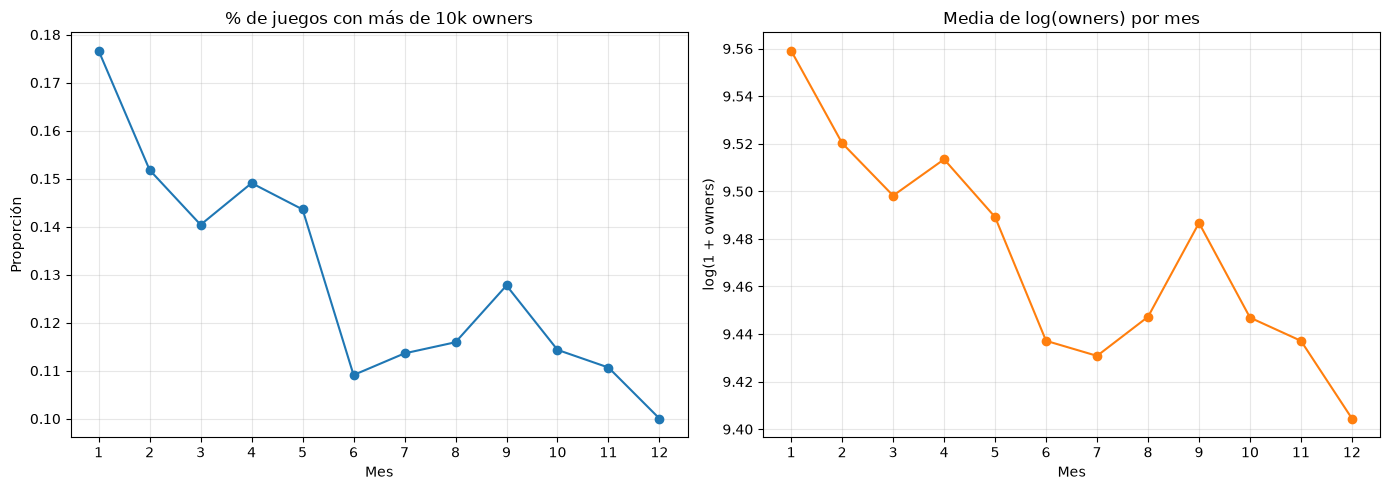

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(groupby_mes["month"], groupby_mes["porciento_exito"], marker="o", linestyle="-")
ax[0].set_title("% de juegos con más de 10k owners")
ax[0].set_xlabel("Mes")
ax[0].set_ylabel("Proporción")
ax[0].set_xticks(range(1, 13))
ax[0].grid(alpha=0.3)

ax[1].plot(groupby_mes["month"], groupby_mes["media_log"], marker="o", linestyle="-", color="tab:orange")
ax[1].set_title("Media de log(owners) por mes")
ax[1].set_xlabel("Mes")
ax[1].set_ylabel("log(1 + owners)")
ax[1].set_xticks(range(1, 13))
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

WOW observacion encontrada!

Los juegos lanzados en enero tienen una mayor cantidad de jugadores, por lo que es nuestro mes "ideal"

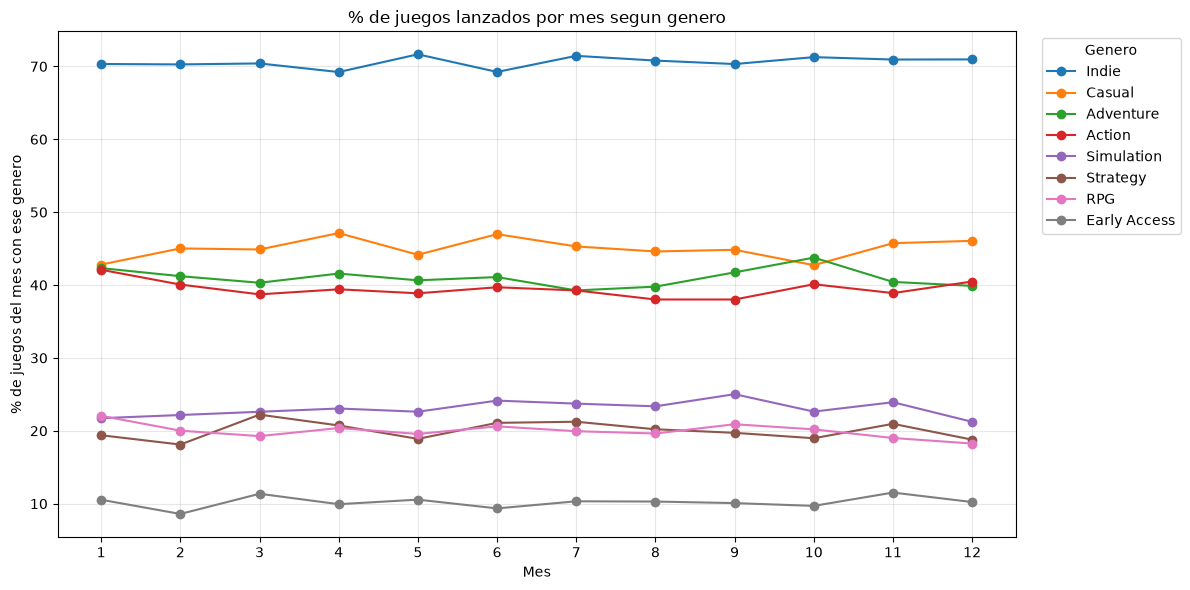

In [56]:
columnas_generos = [f"genre_{i}" for i in range(11)]

# Vamos a hacer una fila por juego/genero, sin usar "Desconocido", ya que no nos sirve.
largo = (
    df.melt(id_vars="month", value_vars=columnas_generos, value_name="genero")
      .query("genero != 'Desconocido'")
)

# Top 8 generos
top = largo["genero"].value_counts().head(8).index

# % de juegos de cada mes por cada genero
tabla = pd.crosstab(largo["month"], largo["genero"])[top]
tabla_porcientos = tabla.div(df.groupby("month").size(), axis=0) * 100

# Tremendo grafico
fig, ax = plt.subplots(figsize=(12, 6))
for g in tabla_porcientos.columns:
    ax.plot(tabla_porcientos.index, tabla_porcientos[g], marker="o", label=g)

ax.set_title("% de juegos lanzados por mes segun genero")
ax.set_xlabel("Mes")
ax.set_ylabel("% de juegos del mes con ese genero")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
ax.legend(title="Genero", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [51]:
largo

,month,variable,genero
0,6,genre_0,Casual
1,8,genre_0,Action
2,10,genre_0,Action
3,8,genre_0,Action
4,5,genre_0,Action
...,...,...,...
414538,6,genre_9,Game Development
414695,8,genre_9,Early Access
414976,9,genre_9,Web Publishing
415814,4,genre_9,Strategy


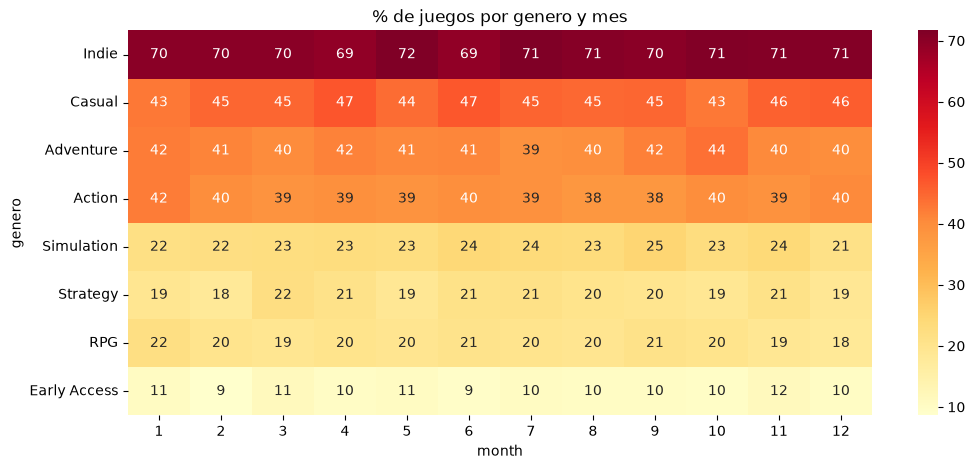

In [52]:

plt.figure(figsize=(12, 5))
sns.heatmap(tabla_porcientos.T, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("% de juegos por genero y mes")
plt.show()

Resultado: casual y aventura son los que mas lanzamientos tienen.

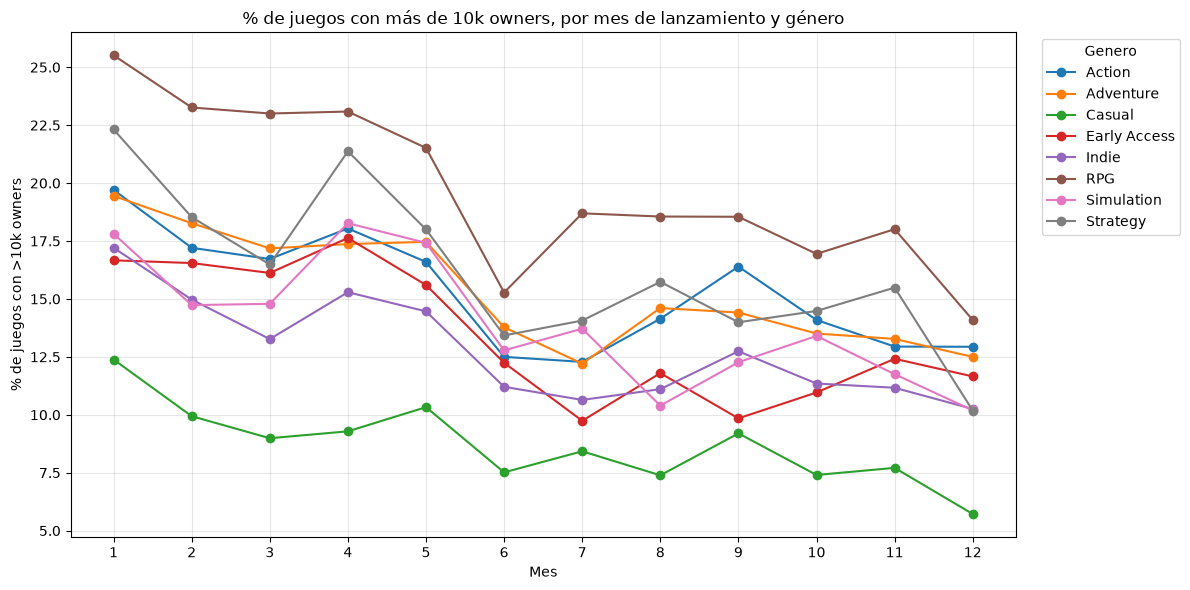

In [57]:
gcols = [f"genre_{i}" for i in range(11)] # Por si acaso la definimos otra vez

largo = (
    df.melt(id_vars=["month", "media_owners", "supera_10k"],
            value_vars=gcols, value_name="genero")
      .query("genero != 'Desconocido'")
)

# Top 8 géneros por número de juegos
top = largo["genero"].value_counts().head(8).index
largo_top = largo[largo["genero"].isin(top)]

# % de éxito por mes y género
exito = (
    largo_top.pivot_table(index="month", columns="genero",
                          values="supera_10k", aggfunc="mean") * 100
)

# Scatter con lineas
fig, ax = plt.subplots(figsize=(12, 6))
for g in exito.columns:
    ax.plot(exito.index, exito[g], marker="o", label=g)

ax.set_title("% de juegos con más de 10k owners, por mes de lanzamiento y género")
ax.set_xlabel("Mes")
ax.set_ylabel("% de juegos con >10k owners")
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)
ax.legend(title="Genero", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

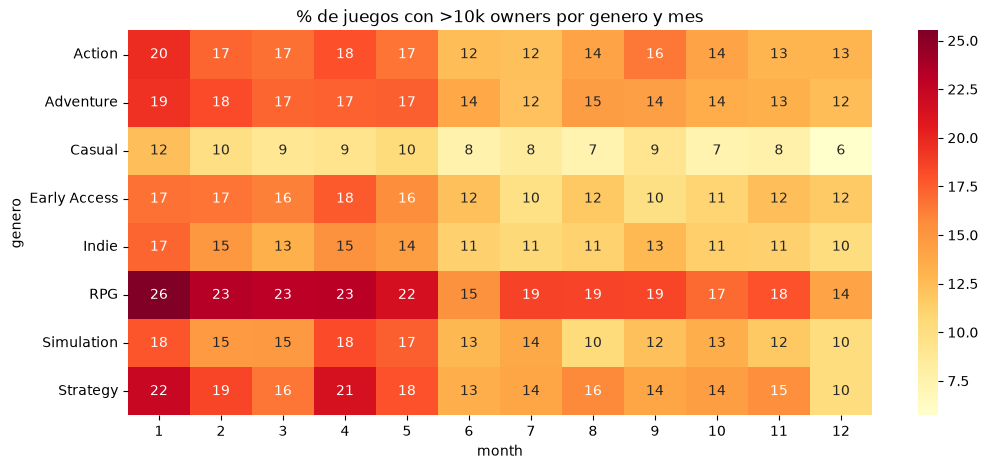

In [58]:

# Y tambien un heatmap que permite verlo mas claro
plt.figure(figsize=(12, 5))
sns.heatmap(exito.T, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("% de juegos con >10k owners por genero y mes")
plt.show()

RPG y simulación son los vencedores en cantidad de usuarios